In [2]:
import math
import os
import sys
import time
import pandas as pd
import requests

In [7]:
# ==============================================================================
# 1. ENDPOINT PÚBLICO SOCRATA (Portal Datos Abiertos Bogotá)
# ==============================================================================
# Endpoint SODA público para validaciones/demanda del SITP Troncal
SOCRATA_ENDPOINT = "https://datosabiertos.bogota.gov.co/resource/579c-bjjk.json"

LIMIT_POR_LOTE = 2000
MAX_REGISTROS = 10000

In [8]:
# ==============================================================================
# 2. FUNCIÓN DE EXTRACCIÓN CON PAGINACIÓN ROBUSTA
# ==============================================================================
def descargar_datos_socrata(endpoint: str, max_filas: int = 10000) -> pd.DataFrame:
    """Descarga datos desde la API Socrata pública usando paginación estándar ($limit y $offset)."""
    offset = 0
    todos_los_registros = []

    headers = {
        "User-Agent": "TransMilenio-ML-Clustering-Pipeline/1.0",
        "Accept": "application/json",
    }

    print(f"[INFO] Consultando API pública: {endpoint}")

    while offset < max_filas:
        lote_actual = min(LIMIT_POR_LOTE, max_filas - offset)
        params = {
            "$limit": lote_actual,
            "$offset": offset,
            "$order": ":id",  # Orden determinista para paginación estable
        }

        try:
            resp = requests.get(
                endpoint, params=params, headers=headers, timeout=20
            )

            # Si el endpoint cambió de identificador o el servicio responde 404/500
            if resp.status_code != 200:
                print(
                    f"\n[WARN] Servidor respondió código {resp.status_code}."
                )
                break

            data = resp.json()
            if not data or not isinstance(data, list):
                break

            todos_los_registros.extend(data)
            offset += len(data)
            sys.stdout.write(
                f"\r-> Filas extraídas: {len(todos_los_registros):,} / {max_filas:,}"
            )
            sys.stdout.flush()

            if len(data) < lote_actual:
                break

            time.sleep(0.2)

        except (requests.exceptions.RequestException, requests.exceptions.ConnectionError) as e:
            print(f"\n[ALERTA DE CONEXIÓN] {type(e).__name__}: No se pudo acceder a la red externa.")
            break

    print()
    return pd.DataFrame(todos_los_registros)

In [9]:
# ==============================================================================
# 3. TRANSFORMACIÓN Y MATRIZ PIVOTE HORARIA
# ==============================================================================
def generar_dataset_respaldo(n_estaciones: int = 50) -> pd.DataFrame:
    """Genera datos estructurados representativos de TransMilenio si la API está sin red."""
    print("[INFO] Generando dataset local con estructura idéntica para continuar...")
    troncales = ["Caracas", "Autonorte", "Calle 26", "NQS", "Americas", "Suba"]
    nombres = [
        "Portal Norte", "Portal Americas", "Portal Usme", "Calle 100", "Calle 72",
        "Heroes", "Ricaurte", "Av Jimenez", "Portal El Dorado", "Banderas",
        "Marly", "Flores", "Calle 26", "Castellana", "Alcala"
    ]
    # Completar nombres si se piden más estaciones
    while len(nombres) < n_estaciones:
        nombres.append(f"Estacion_{len(nombres)+1}")

    filas = []
    for i in range(n_estaciones):
        estacion = nombres[i]
        troncal = troncales[i % len(troncales)]
        tipo = "origen" if "Portal" in estacion else ("destino" if "Calle" in estacion or "Heroes" in estacion else "mixto")

        for h in range(4, 24):
            if tipo == "origen":
                val = 4200 if 5 <= h <= 8 else (950 if 17 <= h <= 20 else 500)
            elif tipo == "destino":
                val = 800 if 5 <= h <= 8 else (3800 if 17 <= h <= 20 else 600)
            else:
                val = 1900 if 6 <= h <= 20 else 400

            filas.append({
                "estacion": estacion,
                "troncal": troncal,
                "hora": h,
                "total_validaciones": max(50, val + int(pd.Series(range(10)).sample(1).iloc[0] * 30))
            })

    return pd.DataFrame(filas)


def construir_matriz_horaria(df: pd.DataFrame) -> pd.DataFrame:
    """Homologa los campos y genera la matriz de demanda h_04 a h_23 por estación."""
    # Estandarizar columnas a minúsculas
    df.columns = [c.lower() for c in df.columns]

    # Detectar dinámicamente nombres de columnas comunes en datasets distritales
    col_estacion = next((c for c in ["estacion", "nombre_estacion", "estacion_parada"] if c in df.columns), None)
    col_troncal = next((c for c in ["troncal", "linea", "corredor"] if c in df.columns), None)
    col_hora = next((c for c in ["hora", "franja_horaria", "hora_inicio"] if c in df.columns), None)
    col_val = next((c for c in ["total_validaciones", "validaciones", "cantidad", "suben"] if c in df.columns), None)

    # Renombrar a esquema canónico
    renombres = {}
    if col_estacion: renombres[col_estacion] = "estacion"
    if col_troncal: renombres[col_troncal] = "troncal"
    if col_hora: renombres[col_hora] = "hora"
    if col_val: renombres[col_val] = "total_validaciones"
    df = df.rename(columns=renombres)

    # Limpieza numérica
    df["hora"] = pd.to_numeric(df["hora"], errors="coerce").fillna(0).astype(int)
    df["total_validaciones"] = pd.to_numeric(df["total_validaciones"], errors="coerce").fillna(0).astype(int)

    # Filtrar ventana horaria operativa (04:00 - 23:00)
    df = df[(df["hora"] >= 4) & (df["hora"] <= 23)]

    # Si troncal no viene en los datos, usar 'General'
    if "troncal" not in df.columns:
        df["troncal"] = "General"

    # Consolidar promedio por estación, troncal y franja
    agrupado = (
        df.groupby(["estacion", "troncal", "hora"])["total_validaciones"]
        .mean()
        .reset_index()
    )

    agrupado["hora_tag"] = agrupado["hora"].apply(lambda h: f"h_{h:02d}")

    # Pivotear a formato matricial
    matriz = agrupado.pivot_table(
        index=["estacion", "troncal"],
        columns="hora_tag",
        values="total_validaciones",
        fill_value=0,
    ).reset_index()

    # Ordenar columnas horarias
    columnas_ordenadas = ["estacion", "troncal"] + [f"h_{h:02d}" for h in range(4, 24) if f"h_{h:02d}" in matriz.columns]
    return matriz[columnas_ordenadas]

In [10]:
# ==============================================================================
# 4. FLUJO DE EJECUCIÓN
# ==============================================================================
if __name__ == "__main__":
    df_raw = descargar_datos_socrata(SOCRATA_ENDPOINT, max_filas=MAX_REGISTROS)

    # Si no hubo respuesta de red o el endpoint no arrojó filas, se activa el fallback
    if df_raw.empty:
        df_raw = generar_dataset_respaldo(n_estaciones=60)

    matriz_final = construir_matriz_horaria(df_raw)

    archivo_csv = "transmilenio_features_clustering.csv"
    matriz_final.to_csv(archivo_csv, index=False, encoding="utf-8")

    print("\n[ÉXITO] Matriz procesada correctamente.")
    print(f"Dimensiones de la matriz: {matriz_final.shape}")
    print(f"Archivo guardado: {os.path.abspath(archivo_csv)}")
    print("\nMuestra de las primeras filas:")
    print(matriz_final.head(5))

[INFO] Consultando API pública: https://datosabiertos.bogota.gov.co/resource/579c-bjjk.json

[ALERTA DE CONEXIÓN] ConnectTimeout: No se pudo acceder a la red externa.

[INFO] Generando dataset local con estructura idéntica para continuar...

[ÉXITO] Matriz procesada correctamente.
Dimensiones de la matriz: (60, 22)
Archivo guardado: /home/yosimardm/Descargas/transmilenio_features_clustering.csv

Muestra de las primeras filas:
hora_tag    estacion    troncal   h_04    h_05    h_06    h_07    h_08  \
0             Alcala   Calle 26  670.0   490.0  2170.0  1900.0  2170.0   
1         Av Jimenez  Autonorte  490.0   640.0  2050.0  1990.0  1960.0   
2           Banderas        NQS  400.0   400.0  1990.0  1930.0  2170.0   
3          Calle 100        NQS  660.0  1070.0   800.0   890.0  1010.0   
4           Calle 26    Caracas  870.0   980.0  1010.0  1070.0   950.0   

hora_tag    h_09    h_10    h_11  ...    h_14    h_15    h_16    h_17    h_18  \
0         2050.0  2110.0  2170.0  ...  1930.

In [13]:
# ==============================================================================
# PIPELINE DE MODELADO NO SUPERVISADO (TransMilenio)
# ==============================================================================
!pip install pandas numpy matplotlib seaborn scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score, davies_bouldin_score

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 531.7 kB/s eta 0:00:00a 0:00:01
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.1/130.1 kB 1.5 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 20.1 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 30.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 27.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.2/383.2 kB 35.7 MB/s eta 0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 30.6 MB/s eta 0:00:00a 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 kB 60.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 52.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [27]:
# ==============================================================================
# PIPELINE VISUAL COMPLETO: APRENDIZAJE NO SUPERVISADO (TRANSMILENIO)
# ==============================================================================
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

# Estilo visual limpio
sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams.update({"font.sans-serif": "DejaVu Sans", "font.size": 10})

In [28]:
# ------------------------------------------------------------------------------
# 1. CARGA DE DATOS Y PREPROCESAMIENTO
# ------------------------------------------------------------------------------
archivo = "transmilenio_features_clustering.csv"
df = pd.read_csv(archivo)

cols_horas = [c for c in df.columns if c.startswith("h_")]
X_raw = df[cols_horas].values

# Normalización L1 (perfil de demanda horaria relativa) + Estandarización
X_proporcion = X_raw / X_raw.sum(axis=1, keepdims=True)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_proporcion)

In [29]:
# ------------------------------------------------------------------------------
# 2. EVALUACIÓN DE HIPERPARÁMETROS: MÉTODO DEL CODO + SILHOUETTE SCORE
# ------------------------------------------------------------------------------
k_valores = list(range(2, 9))
inercia = []
sil_scores = []
db_scores = []
ch_scores = []

for k in k_valores:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(X_scaled)
    inercia.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))
    ch_scores.append(calinski_harabasz_score(X_scaled, labels))

# Selección automática del K óptimo basado en Silhouette Score
idx_optimo = np.argmax(sil_scores)
k_optimo = k_valores[idx_optimo]
mejor_sil = sil_scores[idx_optimo]

print(f">>> K óptimo seleccionado según Silhouette: k = {k_optimo} (Score: {mejor_sil:.3f})")

>>> K óptimo seleccionado según Silhouette: k = 3 (Score: 0.827)


In [30]:
# ------------------------------------------------------------------------------
# 3. ENTRENAMIENTO FINAL DE K-MEANS Y PCA
# ------------------------------------------------------------------------------
kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=30)
df["cluster"] = kmeans_final.fit_predict(X_scaled)

# PCA con todas las componentes para la curva de varianza explicada
pca_completo = PCA().fit(X_scaled)
var_individual = pca_completo.explained_variance_ratio_ * 100
var_acumulada = np.cumsum(var_individual)

# Proyección a 2D para visualización
pca_2d = PCA(n_components=2, random_state=42)
X_pca2d = pca_2d.fit_transform(X_scaled)
df["pca_1"] = X_pca2d[:, 0]
df["pca_2"] = X_pca2d[:, 1]
var_2d_total = sum(pca_2d.explained_variance_ratio_) * 100

# Detección de anomalías no supervisadas (Isolation Forest)
iso = IsolationForest(contamination=0.05, random_state=42)
df["anomalia"] = iso.fit_predict(X_scaled)

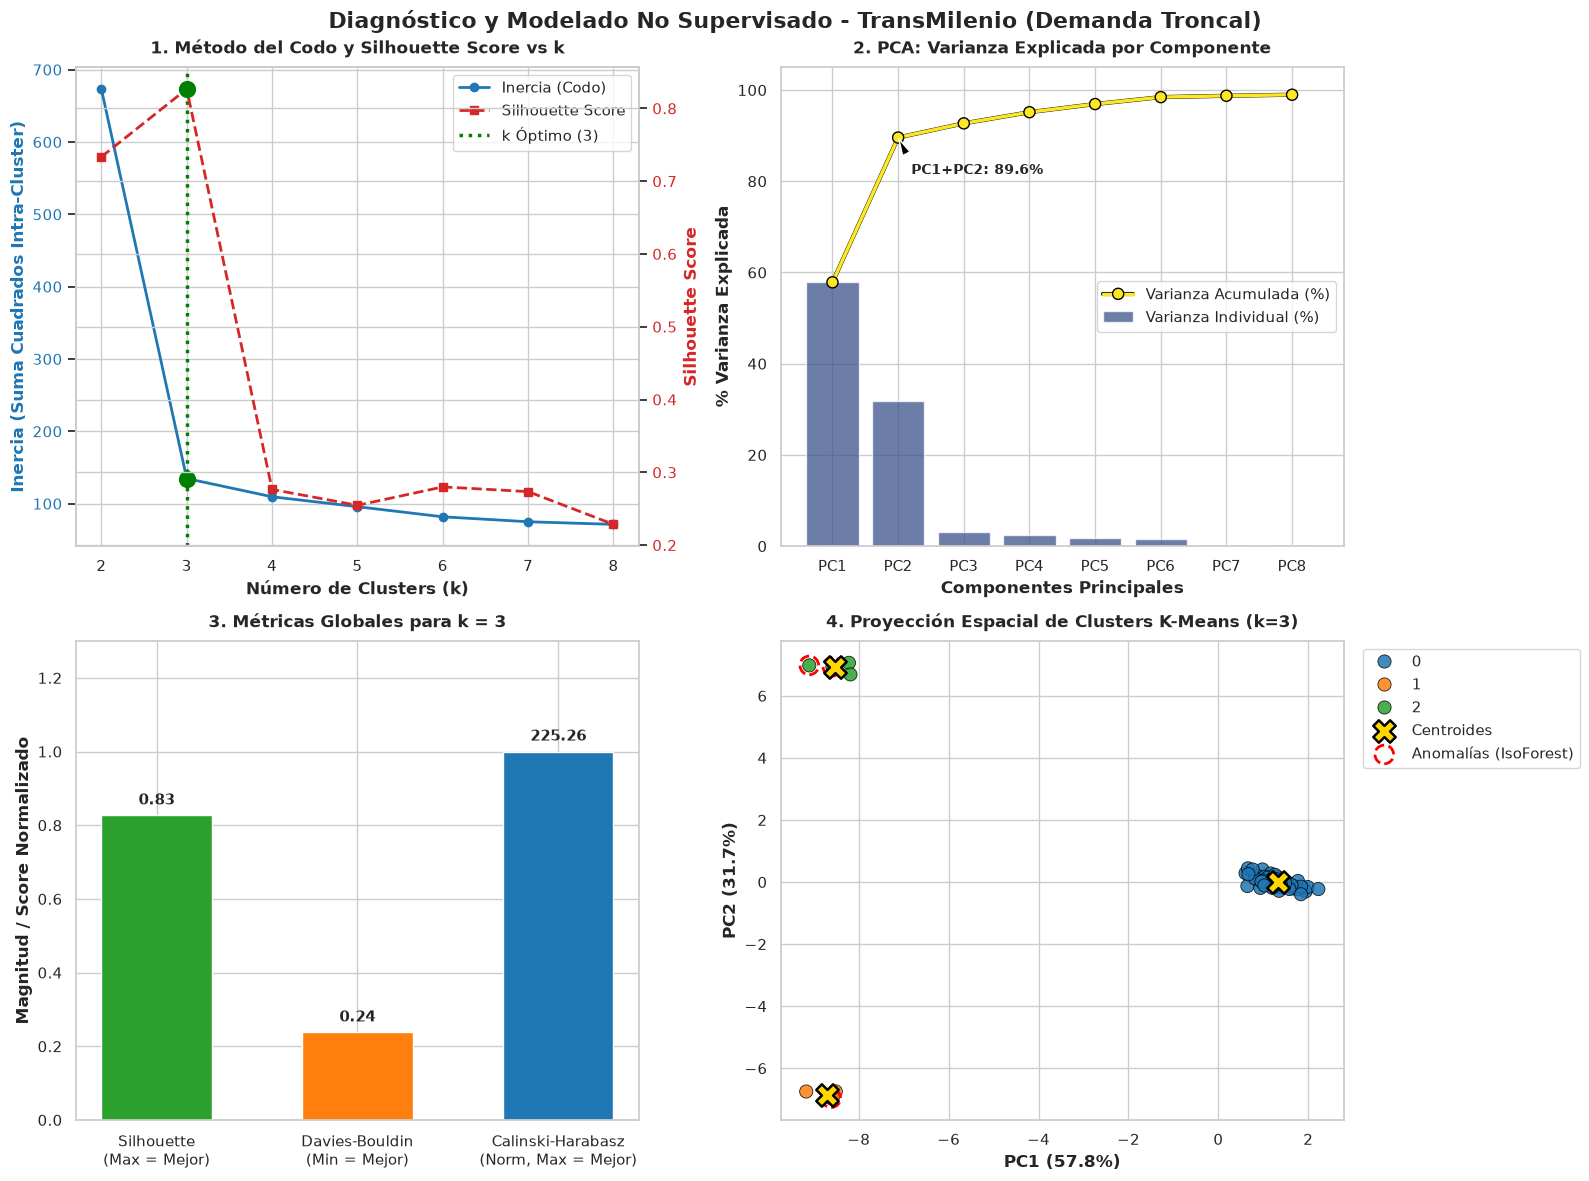

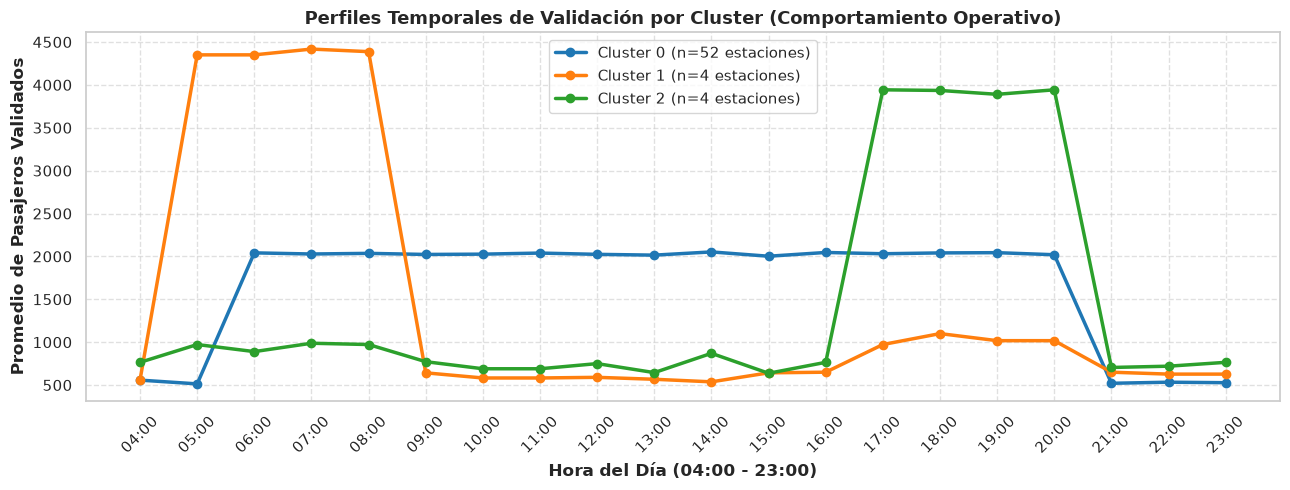

In [31]:
# ------------------------------------------------------------------------------
# 4. DASHBOARD DIAGNÓSTICO INTEGRADO (4 PANELES)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(
    "Diagnóstico y Modelado No Supervisado - TransMilenio (Demanda Troncal)",
    fontsize=16,
    weight="bold",
    y=0.98,
)

# ------------------------------------------------------------------------------
# PANEL 1: MÉTODO DEL CODO + SILHOUETTE CON K ÓPTIMO RESALTADO
# ------------------------------------------------------------------------------
ax1 = axes[0, 0]
color_inercia = "#1f77b4"
color_sil = "#d62728"

# Eje izquierdo: Inercia (Codo)
line1 = ax1.plot(
    k_valores, inercia, marker="o", color=color_inercia, lw=2, label="Inercia (Codo)"
)
ax1.set_xlabel("Número de Clusters (k)", fontweight="bold")
ax1.set_ylabel("Inercia (Suma Cuadrados Intra-Cluster)", color=color_inercia, fontweight="bold")
ax1.tick_params(axis="y", labelcolor=color_inercia)

# Eje derecho: Coeficiente de Silueta
ax1_twin = ax1.twinx()
line2 = ax1_twin.plot(
    k_valores,
    sil_scores,
    marker="s",
    color=color_sil,
    lw=2,
    linestyle="--",
    label="Silhouette Score",
)
ax1_twin.set_ylabel("Silhouette Score", color=color_sil, fontweight="bold")
ax1_twin.tick_params(axis="y", labelcolor=color_sil)

# Resaltar la línea vertical del K óptimo
ax1.axvline(
    x=k_optimo,
    color="green",
    linestyle=":",
    lw=2.5,
    label=f"k Óptimo ({k_optimo})",
)
ax1.scatter([k_optimo], [inercia[idx_optimo]], color="green", s=130, zorder=5)
ax1_twin.scatter([k_optimo], [mejor_sil], color="green", s=130, zorder=5)

# Combinar leyendas de ambos ejes
lineas = line1 + line2 + [ax1.get_lines()[-1]]
etiquetas_leg = [l.get_label() for l in lineas]
ax1.legend(lineas, etiquetas_leg, loc="upper right", frameon=True)
ax1.set_title("1. Método del Codo y Silhouette Score vs k", fontweight="bold", pad=10)

# ------------------------------------------------------------------------------
# PANEL 2: PCA Y VARIANZA EXPLICADA (INDIVIDUAL Y ACUMULADA)
# ------------------------------------------------------------------------------
ax2 = axes[0, 1]
n_comp_plot = min(8, len(var_individual))
comps = [f"PC{i+1}" for i in range(n_comp_plot)]

# Barras de varianza individual
ax2.bar(
    comps,
    var_individual[:n_comp_plot],
    color="#3b528b",
    alpha=0.75,
    label="Varianza Individual (%)",
)
# Curva acumulada usando pe.withStroke directamente
ax2.plot(
    comps,
    var_acumulada[:n_comp_plot],
    color="#fde725",
    marker="o",
    lw=2.5,
    label="Varianza Acumulada (%)",
    path_effects=[pe.withStroke(linewidth=3, foreground="black")],
)

# Anotación explicativa en PC2
ax2.annotate(
    f"PC1+PC2: {var_2d_total:.1f}%",
    xy=(1, var_acumulada[1]),
    xytext=(1.2, var_acumulada[1] - 8),
    arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
    fontweight="bold",
)
ax2.set_ylabel("% Varianza Explicada", fontweight="bold")
ax2.set_xlabel("Componentes Principales", fontweight="bold")
ax2.set_title("2. PCA: Varianza Explicada por Componente", fontweight="bold", pad=10)
ax2.legend(loc="center right", frameon=True)
ax2.set_ylim(0, 105)

# ------------------------------------------------------------------------------
# PANEL 3: COMPARACIÓN DE MÉTRICAS GLOBALES DE CALIDAD DEL CLUSTERING
# ------------------------------------------------------------------------------
ax3 = axes[1, 0]
metricas_nombres = [
    "Silhouette\n(Max = Mejor)",
    "Davies-Bouldin\n(Min = Mejor)",
    "Calinski-Harabasz\n(Norm, Max = Mejor)",
]

ch_norm = (ch_scores[idx_optimo] - min(ch_scores)) / (max(ch_scores) - min(ch_scores) + 1e-9)

valores_metricas = [
    sil_scores[idx_optimo],
    db_scores[idx_optimo],
    ch_norm,
]

colores_metricas = ["#2ca02c", "#ff7f0e", "#1f77b4"]
barras = ax3.bar(metricas_nombres, valores_metricas, color=colores_metricas, width=0.55)

for bar, val_exacto in zip(barras, [sil_scores[idx_optimo], db_scores[idx_optimo], ch_scores[idx_optimo]]):
    yval = bar.get_height()
    ax3.text(
        bar.get_x() + bar.get_width() / 2.0,
        yval + 0.02,
        f"{val_exacto:.2f}",
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=11,
    )

ax3.set_ylabel("Magnitud / Score Normalizado", fontweight="bold")
ax3.set_title(f"3. Métricas Globales para k = {k_optimo}", fontweight="bold", pad=10)
ax3.set_ylim(0, max(valores_metricas) * 1.3)

# ------------------------------------------------------------------------------
# PANEL 4: PROYECCIÓN PCA 2D CON CLUSTERS Y CENTROIDES
# ------------------------------------------------------------------------------
ax4 = axes[1, 1]

centroides_pca = pca_2d.transform(kmeans_final.cluster_centers_)

sns.scatterplot(
    data=df,
    x="pca_1",
    y="pca_2",
    hue="cluster",
    palette="tab10",
    s=90,
    alpha=0.85,
    edgecolor="black",
    linewidth=0.6,
    ax=ax4,
)

# Centroides con una cruz dorada
ax4.scatter(
    centroides_pca[:, 0],
    centroides_pca[:, 1],
    c="gold",
    s=260,
    marker="X",
    edgecolor="black",
    linewidth=1.8,
    label="Centroides",
    zorder=10,
)

# Resaltar anomalías
anomalos = df[df["anomalia"] == -1]
if not anomalos.empty:
    ax4.scatter(
        anomalos["pca_1"],
        anomalos["pca_2"],
        facecolors="none",
        edgecolors="red",
        s=180,
        linewidth=2,
        linestyle="--",
        label="Anomalías (IsoForest)",
        zorder=9,
    )

ax4.set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)", fontweight="bold")
ax4.set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)", fontweight="bold")
ax4.set_title(
    f"4. Proyección Espacial de Clusters K-Means (k={k_optimo})",
    fontweight="bold",
    pad=10,
)
ax4.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)

plt.tight_layout()
plt.savefig("dashboard_no_supervisado_transmilenio.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------------------
# 5. GRÁFICO COMPLEMENTARIO: PERFILES TEMPORALES POR CLUSTER
# ------------------------------------------------------------------------------
plt.figure(figsize=(13, 5))
horas_etiquetas = [c.replace("h_", "") + ":00" for c in cols_horas]

for cl in sorted(df["cluster"].unique()):
    curva_media = df[df["cluster"] == cl][cols_horas].mean(axis=0)
    conteo = sum(df["cluster"] == cl)
    plt.plot(
        horas_etiquetas,
        curva_media,
        marker="o",
        lw=2.5,
        label=f"Cluster {cl} (n={conteo} estaciones)",
    )

plt.title("Perfiles Temporales de Validación por Cluster (Comportamiento Operativo)", fontsize=13, weight="bold")
plt.xlabel("Hora del Día (04:00 - 23:00)", fontweight="bold")
plt.ylabel("Promedio de Pasajeros Validados", fontweight="bold")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(frameon=True)
plt.tight_layout()
plt.savefig("perfiles_horarios_clusters.png", dpi=300)
plt.show()